# Controlled Seq2Point experiment: washing-machine disaggregation

Preserve the verified Random Forest notebook, model, results and earlier cutoff experiment. This notebook trains **one modest CNN** and compares Random Forest, raw CNN and validation-selected CNN post-processing. No additional algorithms or split changes.

Train **2/3/8/9**, validate **5**, evaluate **7/10**, January–March 2015. The evaluation homes are **previously examined retrospective households**, not blind tests. CNN windows contain 49 past, current and **49 future minutes**: this is **offline disaggregation** with at least 49 minutes of look-ahead, unlike the causal RF. Temporal run processing is offline too. Any gain would not be an equal-latency comparison.

Install the project dependencies from `requirements.txt`, including TensorFlow 2.21.0. In VS Code, select the environment's Python notebook kernel, then Restart & Run All. Only a comparison CSV, two figures and a CNN model **if selected** are exported; no scripts/manifests/intermediate prediction files.

Reference: [Zhang et al., Seq2Point](https://arxiv.org/abs/1612.09106), [TensorFlow input pipelines](https://www.tensorflow.org/guide/data), [Keras EarlyStopping](https://keras.io/api/callbacks/early_stopping/). Adopt the midpoint-regression idea, not published performance claims or a large architecture unchanged. A 99-point window here means 99 **minutes**, not 99 original REFIT samples.

The helper functions are intentionally copied from the Part 3 Model notebook so each notebook runs standalone.

## 1. Fixed experiment and acceptance rules

Use a 99-minute input, batch size 512, Adam 0.001, MSE, maximum 10 epochs and patience 2, restoring the epoch with lowest **House 5** loss. These are fixed exploratory settings; no architecture search. Train at natural class proportions. Actual activity remains **>20 W**. Inputs are normalised with training-only mean/variance; target and output units are watts.

Post-processing candidates `(maximum gap, minimum run)` in minutes: **(0,0), (0,5), (0,15), (5,5), (10,15)**. Gaps are bridged only if strictly shorter than the maximum; a run must be at least the minimum duration, including bridged pauses. These are validation assumptions, not physical laws. Missing aggregate/prediction gaps and household boundaries are never bridged.

Retain a processed CNN policy only if it does not reduce raw-CNN F1, loses at most 0.03 recall, does not increase daily energy error, stays within 1% RMSE, and either gains >=0.01 F1 or reduces false-positive minutes by >=10%. Otherwise use no processing.

Recommend CNN instead of RF only if the raw or accepted processed CNN gains >=0.01 F1 on **matched House 5 minutes**, loses at most 0.03 recall, does not increase false-positive minutes or daily energy error, and stays within 1% RF RMSE. Break ties by F1, daily error, then RMSE. These declared practical tolerances are not significance tests. Freeze the recommendation and processing before loading Houses 7/10. A rejected processed policy is never rescued using evaluation results.

In [1]:
from pathlib import Path
from time import perf_counter
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import tensorflow as tf
from sklearn.metrics import precision_score, recall_score, f1_score
from threadpoolctl import threadpool_limits
from IPython.display import display

tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()
thread_limit = threadpool_limits(limits=4)
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
CLEAN_DIR = ROOT/'clean'
PART2_DIR = ROOT/'outputs/part2'
TRAIN_HOUSES = [2,3,8,9]
VALIDATION_HOUSE = 5
TEST_HOUSES = [7,10]
CHANNELS = {2:'Appliance2',3:'Appliance6',5:'Appliance3',7:'Appliance5',
            8:'Appliance4',9:'Appliance3',10:'Appliance5'}
START = pd.Timestamp('2015-01-01',tz='UTC')
END = pd.Timestamp('2015-04-01',tz='UTC')
GRID = pd.date_range(START,END,freq='1min',inclusive='left')
LOCAL_TZ = 'Europe/London'
ACTIVE_W = 20
WINDOW = 99
HALF = WINDOW//2
BATCH_SIZE = 512
POST_RULES = [(0,0),(0,5),(0,15),(5,5),(10,15)]
assert len(set(TRAIN_HOUSES+[VALIDATION_HOUSE]+TEST_HOUSES)) == 7
rf_bundle = joblib.load(ROOT/'results/washing_machine_model.joblib')
rf_model = rf_bundle['model']
feature_columns = rf_bundle['feature_names']
print('TensorFlow:',tf.__version__,'| GPUs:',len(tf.config.list_physical_devices('GPU')))

TensorFlow: 2.21.0 | GPUs: 0


## 2. Reuse baseline preparation and RF features unchanged

The following functions are copied unchanged from the baseline, not a new cleaning pipeline. Reuse Part 2 minute exports where available; all other homes use the same official-cleaned sorting, duplicate handling, outlier masking and minute averaging. Add no interpolation or zero imputation. Source forward-filled/zeroed measurements remain ambiguous, and Issues flags remain metadata.

RF still needs 61 complete aggregate minutes. CNN needs 99 complete centred aggregate minutes and only the midpoint target. Training-window coverage therefore differs; report it. For validation selection and evaluation use the **intersection** of RF eligibility and CNN availability, with unchanged finite target labels. No symmetric padding is used: discard unavailable edge windows rather than invent observations.

In [2]:
def load_house(house):
    power_path = PART2_DIR / f'house{house}_1min.csv.gz'
    quality_path = PART2_DIR / f'house{house}_quality.csv.gz'
    if house in [2, 3, 5] and power_path.exists() and quality_path.exists():
        power = pd.read_csv(power_path, index_col=0, parse_dates=True)
        quality = pd.read_csv(quality_path, index_col=0, parse_dates=True)
        flags = quality['issue_flagged']
        source = 'Part 2 export'
    else:
        channel = CHANNELS[house]
        path = CLEAN_DIR / f'CLEAN_House{house}.csv'
        if not path.is_file():
            raise FileNotFoundError(f'Provide the official cleaned dataset at {path}')
        pieces = []
        for chunk in pd.read_csv(path, usecols=['Unix', 'Aggregate', channel, 'Issues'], chunksize=500_000):
            take = chunk['Unix'].between(START.timestamp(), END.timestamp(), inclusive='left')
            if take.any():
                pieces.append(chunk.loc[take])
        if not pieces:
            raise ValueError(f'House {house}: no readings in the selected period')
        raw = pd.concat(pieces).rename(columns={channel: 'washing_machine'})
        raw = raw.sort_values('Unix', kind='stable').groupby('Unix').agg(
            {'Aggregate': 'last', 'washing_machine': 'last', 'Issues': 'max'})
        raw.index = pd.to_datetime(raw.index, unit='s', utc=True)
        power = raw[['Aggregate', 'washing_machine']].astype('float32')
        power = power.mask((power < 0) | ~np.isfinite(power))
        power['washing_machine'] = power['washing_machine'].mask(power['washing_machine'] > 4000)
        power = power.resample('1min').mean().reindex(GRID)
        flags = raw['Issues'].ne(0).resample('1min').max().reindex(GRID).eq(True)
        source = path.name
    assert power.index.equals(GRID) and flags.index.equals(GRID)
    assert list(power.columns) == ['Aggregate', 'washing_machine']
    assert flags.isin([True, False]).all()
    assert not np.isinf(power).any().any() and not (power < 0).any().any()
    assert power.washing_machine.dropna().le(4000).all()
    power.index.name = 'timestamp_utc'
    return power, flags.astype(bool), source

def make_features(aggregate):
    features = pd.DataFrame({'aggregate_W': aggregate})
    for lag in [1, 5, 15, 60]:
        features[f'lag_{lag}'] = aggregate.shift(lag)
    for window in [15, 60]:
        history = aggregate.rolling(window, min_periods=window)
        features[f'mean_{window}'] = history.mean()
        features[f'std_{window}'] = history.std()
    features['change_1'] = aggregate.diff()
    local = aggregate.index.tz_convert(LOCAL_TZ)
    features['hour'] = local.hour
    features['weekday'] = local.day_of_week
    complete = aggregate.rolling(61, min_periods=61).count().eq(61)
    return features.where(complete)

def evaluate(actual, predicted):
    y = actual.to_numpy(dtype=float)
    p = np.asarray(predicted, dtype=float)
    assert len(y) > 0 and y.shape == p.shape and np.isfinite(y).all() and np.isfinite(p).all()
    assert actual.index.is_unique and actual.index.is_monotonic_increasing
    on, predicted_on = y > ACTIVE_W, p > ACTIVE_W
    daily = pd.DataFrame({'actual': y, 'predicted': p}, index=actual.index.tz_convert(LOCAL_TZ))
    daily = daily.resample('1D').sum(min_count=1)
    energy = y.sum()
    return {'minutes': len(y), 'MAE_W': np.abs(y-p).mean(), 'RMSE_W': np.sqrt(np.mean((y-p)**2)),
            'precision': precision_score(on, predicted_on, zero_division=0),
            'recall': recall_score(on, predicted_on, zero_division=0),
            'F1': f1_score(on, predicted_on, zero_division=0),
            'actual_kWh': energy/60000, 'predicted_kWh': p.sum()/60000,
            'energy_bias_percent': 100*(p.sum()-energy)/energy if energy else np.nan,
            'daily_energy_error_percent': 100*(daily.predicted-daily.actual).abs().sum()/energy if energy else np.nan}

def predict_power(model, table):
    if model is None:
        return np.zeros(len(table))
    return np.clip(model.predict(table[feature_columns]), 0, table.aggregate_W.to_numpy())

In [3]:
def window_centres(aggregate,target=None):
    values = np.asarray(aggregate,dtype=np.float32)
    if len(values)<WINDOW:
        return np.empty(0,dtype=np.int64)
    finite = np.lib.stride_tricks.sliding_window_view(np.isfinite(values),WINDOW).all(axis=1)
    centres = np.flatnonzero(finite)+HALF
    if target is not None:
        centres = centres[np.isfinite(np.asarray(target)[centres])]
    return centres.astype(np.int64)

def rf_table(power):
    table = make_features(power.Aggregate)
    table['target_W'] = power.washing_machine
    return table.dropna()

power_data = {h:load_house(h)[0] for h in TRAIN_HOUSES+[VALIDATION_HOUSE]}
centres = {h:window_centres(power_data[h].Aggregate,power_data[h].washing_machine)
           for h in TRAIN_HOUSES+[VALIDATION_HOUSE]}
validation_rf = rf_table(power_data[VALIDATION_HOUSE])
validation_positions = centres[VALIDATION_HOUSE]
validation_positions = validation_positions[GRID[validation_positions].isin(validation_rf.index)]
assert len(validation_positions)>0
# Concatenate only after computing each home's centres, so windows stay inside each home.
training_aggregate,training_target,training_centres = [],[],[]
offset = 0
for house in TRAIN_HOUSES:
    power = power_data[house]
    training_aggregate.append(power.Aggregate.to_numpy(dtype=np.float32))
    training_target.append(power.washing_machine.to_numpy(dtype=np.float32))
    training_centres.append(centres[house]+offset)
    offset += len(power)
training_aggregate = np.concatenate(training_aggregate)
training_target = np.concatenate(training_target)
training_centres = np.concatenate(training_centres)
input_mean = float(np.nanmean(training_aggregate,dtype=np.float64))
input_variance = float(np.nanvar(training_aggregate,dtype=np.float64))
assert input_variance>0
coverage_rows = [{'house':h,'grid_minutes':len(GRID),'RF_eligible':len(rf_table(power_data[h])),
                  'CNN_labelled_centres':len(centres[h])} for h in TRAIN_HOUSES+[VALIDATION_HOUSE]]
display(pd.DataFrame(coverage_rows).set_index('house'))
print('CNN training windows:',len(training_centres),'| matched validation minutes:',len(validation_positions))

,grid_minutes,RF_eligible,CNN_labelled_centres
house,,,
2,129600,122939,121951
3,129600,123701,122979
8,129600,123775,123091
9,129600,124197,123741
5,129600,121077,119050


CNN training windows: 491762 | matched validation minutes: 118478


## 3. Efficient batched windows and a small CNN

Keep only one-dimensional source arrays and centre indices in memory. Gather `(batch,99,1)` windows **after batching** with tf.data; do not allocate the full overlapping feature array. Seeded shuffling affects training only. The per-house centre checks guarantee no window crosses an outage or household boundary, even after concatenation.

Three Conv1D/ReLU layers (16/24/32 filters, kernels 7/5/3), dropout 0.1, flatten, dense 32/ReLU and one linear regression unit. Training-only normalisation is embedded in the model. A fixed output scale of 1000 converts the linear unit to watts; this is not a fitted target transformation. MSE and early stopping use unchanged watt labels. Negative predictions are allowed internally; inference applies the same nonnegative, per-minute aggregate cap as RF.

In [4]:
def make_dataset(aggregate,positions,target=None,shuffle=False):
    values = tf.convert_to_tensor(np.asarray(aggregate,dtype=np.float32))
    labels = None if target is None else tf.convert_to_tensor(np.asarray(target,dtype=np.float32))
    offsets = tf.range(-HALF,HALF+1,dtype=tf.int64)
    dataset = tf.data.Dataset.from_tensor_slices(np.asarray(positions,dtype=np.int64))
    if shuffle:
        dataset = dataset.shuffle(min(len(positions),100000),seed=42,reshuffle_each_iteration=True)
    def gather_batch(batch_centres):
        windows = tf.gather(values,batch_centres[:,None]+offsets)[...,None]
        return windows if labels is None else (windows,tf.gather(labels,batch_centres)[:,None])
    options = tf.data.Options()
    options.deterministic = True
    options.threading.private_threadpool_size = 4
    return dataset.batch(BATCH_SIZE).map(gather_batch).with_options(options).prefetch(1)

def build_seq2point(mean,variance):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(WINDOW,1)),
        tf.keras.layers.Normalization(mean=[mean],variance=[variance]),
        tf.keras.layers.Conv1D(16,7,activation='relu'),
        tf.keras.layers.Conv1D(24,5,activation='relu'),
        tf.keras.layers.Conv1D(32,3,activation='relu'),
        tf.keras.layers.Dropout(.1),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(32,activation='relu'),
        tf.keras.layers.Dense(1,activation='linear'),
        tf.keras.layers.Rescaling(1000.,name='watts')],name='seq2point_99min')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001),loss='mse')
    return model

training_ds = make_dataset(training_aggregate,training_centres,training_target,shuffle=True)
validation_power = power_data[VALIDATION_HOUSE]
validation_ds = make_dataset(validation_power.Aggregate,validation_positions,validation_power.washing_machine)
cnn = build_seq2point(input_mean,input_variance)
print('CNN parameters:',cnn.count_params())
stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=2,min_delta=1.,restore_best_weights=True)
start = perf_counter()
history = cnn.fit(training_ds,validation_data=validation_ds,epochs=10,callbacks=[stop],verbose=2,shuffle=False)
training_seconds = perf_counter()-start
print(f'Actual training: {len(history.history["loss"])} epochs, {training_seconds:.1f} seconds')

CNN parameters: 93561
Epoch 1/10


961/961 - 58s - 60ms/step - loss: 26587.7402 - val_loss: 43224.0273


Epoch 2/10


961/961 - 82s - 86ms/step - loss: 18083.2051 - val_loss: 44115.5977


Epoch 3/10


...

Epoch 6/10


961/961 - 84s - 88ms/step - loss: 9916.6475 - val_loss: 41523.6328


Epoch 7/10


961/961 - 82s - 85ms/step - loss: 8937.1592 - val_loss: 42545.4688


Actual training: 7 epochs, 578.5 seconds


## 4. Deterministic offline state processing

Activity masks and wattage estimates are separate. Bridge a short inactive interval only between active runs within one contiguous observed block; then remove runs shorter than the chosen duration. A bridged zero stays **0 W**: no interpolation or invented washer energy. Bridging can help short runs qualify as one longer episode, but the event mask may be True while wattage remains <=20 W.

For fair primary precision/recall/F1, always derive activity from the final **wattage >20 W** for RF and both CNN policies. Show event-mask F1 separately as a diagnostic; never substitute it to inflate the main score. Keep low/off wattage outside removed activity runs unchanged so `(0,0)` is an identity policy. Observation gaps stay NaN and break runs. Output wattage is capped by each minute's aggregate, not the home's global maximum.

In [5]:
def true_runs(mask):
    edges = np.flatnonzero(np.diff(np.r_[False,np.asarray(mask,dtype=bool),False]))
    return edges.reshape(-1,2)

def postprocess(prediction,aggregate,max_gap=0,min_duration=0):
    if not prediction.index.equals(aggregate.index):
        raise ValueError('Prediction and aggregate timestamps must match')
    if not prediction.index.equals(GRID):
        raise ValueError('Process one household on the full regular minute grid')
    if max_gap<0 or min_duration<0:
        raise ValueError('Durations must be nonnegative')
    p = prediction.to_numpy(dtype=float)
    a = aggregate.to_numpy(dtype=float)
    valid = np.isfinite(p)&np.isfinite(a)&(a>=0)
    output = np.full(len(p),np.nan)
    state = np.zeros(len(p),dtype=bool)
    for start,end in true_runs(valid):
        watts = np.clip(p[start:end],0,a[start:end])
        original_on = watts>ACTIVE_W
        retained = original_on.copy()
        runs = true_runs(original_on)
        for (_,left_end),(right_start,_) in zip(runs[:-1],runs[1:]):
            if right_start-left_end<max_gap:
                retained[left_end:right_start] = True
        for left,right in true_runs(retained):
            if right-left<min_duration:
                retained[left:right] = False
        watts[original_on & ~retained] = 0
        output[start:end] = watts
        state[start:end] = retained
    return pd.Series(output,index=GRID),pd.Series(state,index=GRID)

def cnn_prediction(model,power):
    positions = window_centres(power.Aggregate)
    output = pd.Series(np.nan,index=GRID,dtype=float)
    if len(positions):
        dataset = make_dataset(power.Aggregate,positions)
        raw = model.predict(dataset,verbose=0).ravel()
        output.iloc[positions] = np.clip(raw,0,power.Aggregate.iloc[positions].to_numpy())
    return output

def score(actual,predicted):
    row = evaluate(actual,predicted)
    y,p = actual.to_numpy(),np.asarray(predicted)
    active = y>ACTIVE_W
    high = y>1000
    row['false_positive_minutes'] = int(((p>ACTIVE_W)&~active).sum())
    row['missed_active_minutes'] = int(((p<=ACTIVE_W)&active).sum())
    row['high_power_minutes'] = int(high.sum())
    row['high_power_MAE_W'] = np.abs(p[high]-y[high]).mean() if high.any() else np.nan
    row['high_power_bias_W'] = (p[high]-y[high]).mean() if high.any() else np.nan
    return row

## 5. House 5 comparison and post-processing selection

Early stopping used House 5 only. All rows in this table use the same RF/CNN intersection; report the full-coverage saved RF row separately for context, not as a like-for-like improvement comparison. No evaluation household has been loaded yet.

In [6]:
validation_cnn = cnn_prediction(cnn,validation_power)
matched_index = GRID[validation_positions]
y_validation = validation_power.washing_machine.loc[matched_index]
rf_validation_p = predict_power(rf_model,validation_rf.loc[matched_index])
rf_validation = score(y_validation,rf_validation_p)
cnn_raw_validation = score(y_validation,validation_cnn.loc[matched_index])
post_rows = []
for gap,duration in POST_RULES:
    processed,mask = postprocess(validation_cnn,validation_power.Aggregate,gap,duration)
    row = score(y_validation,processed.loc[matched_index])
    row.update(max_gap=gap,min_duration=duration,
               event_mask_F1=f1_score(y_validation>ACTIVE_W,mask.loc[matched_index],zero_division=0))
    post_rows.append(row)
post_table = pd.DataFrame(post_rows)
b = cnn_raw_validation
post_table['eligible'] = ((post_table.F1>=b['F1']) & (post_table.recall>=b['recall']-.03) &
                         (post_table.daily_energy_error_percent<=b['daily_energy_error_percent']) &
                         (post_table.RMSE_W<=b['RMSE_W']*1.01) &
                         ((post_table.F1>=b['F1']+.01) |
                          ((b['false_positive_minutes']>0) & (post_table.false_positive_minutes<=.9*b['false_positive_minutes']))))
passing = post_table[post_table.eligible]
post_choice = (post_table.iloc[0] if passing.empty else passing.sort_values(
    ['F1','daily_energy_error_percent','RMSE_W'],ascending=[False,True,True]).iloc[0])
chosen_gap,chosen_duration = int(post_choice.max_gap),int(post_choice.min_duration)
display(post_table[['max_gap','min_duration','precision','recall','F1','event_mask_F1','RMSE_W',
                    'daily_energy_error_percent','false_positive_minutes','missed_active_minutes','eligible']].round(3))
validation_rows = []
for name,metrics in [('RandomForest',rf_validation),('CNN_raw',cnn_raw_validation),('CNN_post',post_choice.to_dict())]:
    row = dict(metrics,house=5,split='validation',model=name)
    validation_rows.append(row)
validation_comparison = pd.DataFrame(validation_rows)
r = rf_validation
validation_comparison['eligible_over_RF'] = ((validation_comparison.model!='RandomForest') &
    (validation_comparison.F1>=r['F1']+.01) & (validation_comparison.recall>=r['recall']-.03) &
    (validation_comparison.false_positive_minutes<=r['false_positive_minutes']) &
    (validation_comparison.daily_energy_error_percent<=r['daily_energy_error_percent']) &
    (validation_comparison.RMSE_W<=r['RMSE_W']*1.01))
passing = validation_comparison[validation_comparison.eligible_over_RF]
selected_name = 'RandomForest' if passing.empty else passing.sort_values(
    ['F1','daily_energy_error_percent','RMSE_W'],ascending=[False,True,True]).iloc[0]['model']
metric_columns = ['minutes','MAE_W','RMSE_W','precision','recall','F1','false_positive_minutes',
                  'missed_active_minutes','energy_bias_percent','daily_energy_error_percent','high_power_MAE_W','high_power_bias_W']
display(validation_comparison.set_index('model')[metric_columns+['eligible_over_RF']].round(3))
print('Frozen processing:',chosen_gap,chosen_duration,'| frozen model recommendation:',selected_name)
# From this point onward no epoch, model or processing decision changes.

,max_gap,min_duration,precision,recall,F1,event_mask_F1,RMSE_W,daily_energy_error_percent,false_positive_minutes,missed_active_minutes,eligible
0,0,0,0.367,0.227,0.281,0.281,202.240,85.183,4332,8543,False
1,0,5,0.376,0.216,0.274,0.274,202.413,85.198,3956,8670,False
2,0,15,0.380,0.164,0.229,0.229,206.669,87.161,2964,9241,False
3,5,5,0.371,0.222,0.278,0.286,202.336,85.172,4175,8596,False
4,10,15,0.363,0.199,0.257,0.271,204.490,86.268,3874,8851,False


,minutes,MAE_W,RMSE_W,precision,recall,F1,false_positive_minutes,missed_active_minutes,energy_bias_percent,daily_energy_error_percent,high_power_MAE_W,high_power_bias_W,eligible_over_RF
model,,,,,,,,,,,,,
RandomForest,118478,50.386,205.577,0.266,0.399,0.319,12155,6647,-38.403,91.292,1722.675,-1722.675,False
CNN_raw,118478,42.324,202.240,0.367,0.227,0.281,4332,8543,-64.163,85.183,1689.226,-1684.638,False
CNN_post,118478,42.324,202.240,0.367,0.227,0.281,4332,8543,-64.163,85.183,1689.226,-1684.638,False


Frozen processing: 0 0 | frozen model recommendation: RandomForest


## 6. Evaluate the frozen models on retrospective homes

Compare all three requested approaches on identical RF/CNN-eligible observations in each home. The processed CNN uses only the House 5-selected policy. Report coverage and both improved and worsened metrics. No retuning or household replacement follows this evaluation.

In [7]:
all_rows = validation_rows.copy()
evaluation_frames = {}
for house in TEST_HOUSES:
    power_data[house] = load_house(house)[0]
    power = power_data[house]
    table = rf_table(power)
    raw = cnn_prediction(cnn,power)
    processed,_ = postprocess(raw,power.Aggregate,chosen_gap,chosen_duration)
    common = table.index.intersection(raw.dropna().index)
    frame = pd.DataFrame({'actual_W':power.washing_machine.loc[common],
                          'aggregate_W':power.Aggregate.loc[common],
                          'RandomForest':predict_power(rf_model,table.loc[common]),
                          'CNN_raw':raw.loc[common], 'CNN_post':processed.loc[common]})
    evaluation_frames[house] = frame
    coverage_rows.append({'house':house,'grid_minutes':len(GRID),'RF_eligible':len(table),
                          'CNN_labelled_centres':len(window_centres(power.Aggregate,power.washing_machine)),
                          'matched_minutes':len(frame)})
    for name in ['RandomForest','CNN_raw','CNN_post']:
        all_rows.append(dict(score(frame.actual_W,frame[name]),house=house,split=f'test_house{house}',model=name))
comparison = pd.DataFrame(all_rows)
display(comparison.set_index(['split','model'])[metric_columns].round(3))
coverage_table = pd.DataFrame(coverage_rows).set_index('house')
coverage_table.loc[5,'matched_minutes'] = len(matched_index)
display(coverage_table)
print('Training seconds:',round(training_seconds,1),'| epochs:',len(history.history['loss']))
print('Recommendation remains:',selected_name)

minutes   MAE_W   RMSE_W  precision  recall     F1  \
split        model                                                              
validation   RandomForest   118478  50.386  205.577      0.266   0.399  0.319   
             CNN_raw        118478  42.324  202.240      0.367   0.227  0.281   
             CNN_post       118478  42.324  202.240      0.367   0.227  0.281   
test_house7  RandomForest   122638  49.144  220.000      0.409   0.771  0.534   
             CNN_raw        122638  36.053  161.467      0.534   0.813  0.645   
             CNN_post       122638  36.053  161.467      0.534   0.813  0.645   
test_house10 RandomForest   118417  42.486  172.277      0.305   0.714  0.428   
             CNN_raw        118417  32.674  157.024      0.464   0.695  0.557   
             CNN_post       118417  32.674  157.024      0.464   0.695  0.557   

                           false_positive_minutes  missed_active_minutes  \
split        model                                                         
validation   RandomForest                   12155                   6647   
             CNN_raw                         4332                   8543   
             CNN_post                        4332                   8543   
test_house7  RandomForest                   11445                   2352   
             CNN_raw                         7289                   1914   
             CNN_post                        7289                   1914   
test_house10 RandomForest                   13885                   2440   
             CNN_raw                         6860                   2602   
             CNN_post                        6860                   2602   

                           energy_bias_percent  daily_energy_error_percent  \
split        model                                                           
validation   RandomForest              -38.403                      91.292   
             CNN_raw                   -64.163                      85.183   
             CNN_post                  -64.163                      85.183   
test_house7  RandomForest              -28.668                      41.027   
             CNN_raw                    27.322                      35.294   
             CNN_post                   27.322                      35.294   
test_house10 RandomForest               20.335                      77.583   
             CNN_raw                    16.311                      66.153   
             CNN_post                   16.311                      66.153   

                           high_power_MAE_W  high_power_bias_W  
split        model                                              
validation   RandomForest          1722.675          -1722.675  
             CNN_raw               1689.226          -1684.638  
             CNN_post              1689.226          -1684.638  
test_house7  RandomForest          1510.856          -1510.706  
             CNN_raw                558.158           -311.685  
             CNN_post               558.158           -311.685  
test_house10 RandomForest          1290.409          -1290.409  
             CNN_raw                852.700           -799.392  
             CNN_post               852.700           -799.392

,grid_minutes,RF_eligible,CNN_labelled_centres,matched_minutes
house,,,,
2,129600,122939,121951,NaN
3,129600,123701,122979,NaN
8,129600,123775,123091,NaN
9,129600,124197,123741,NaN
5,129600,121077,119050,118478.0
7,129600,123373,122803,122638.0
10,129600,119868,118728,118417.0


Training seconds: 578.5 | epochs: 7
Recommendation remains: RandomForest


## 7. Actual versus predicted and observed failures

Choose one well-covered active local day in each evaluation home closest to median measured eligible-day energy. This is an illustration after evaluation, not model selection. Failure windows centre the largest false-positive and missed-active watt errors of the validation-selected CNN policy, showing RF for comparison. Do not infer the identity of an interfering appliance from aggregate alone.

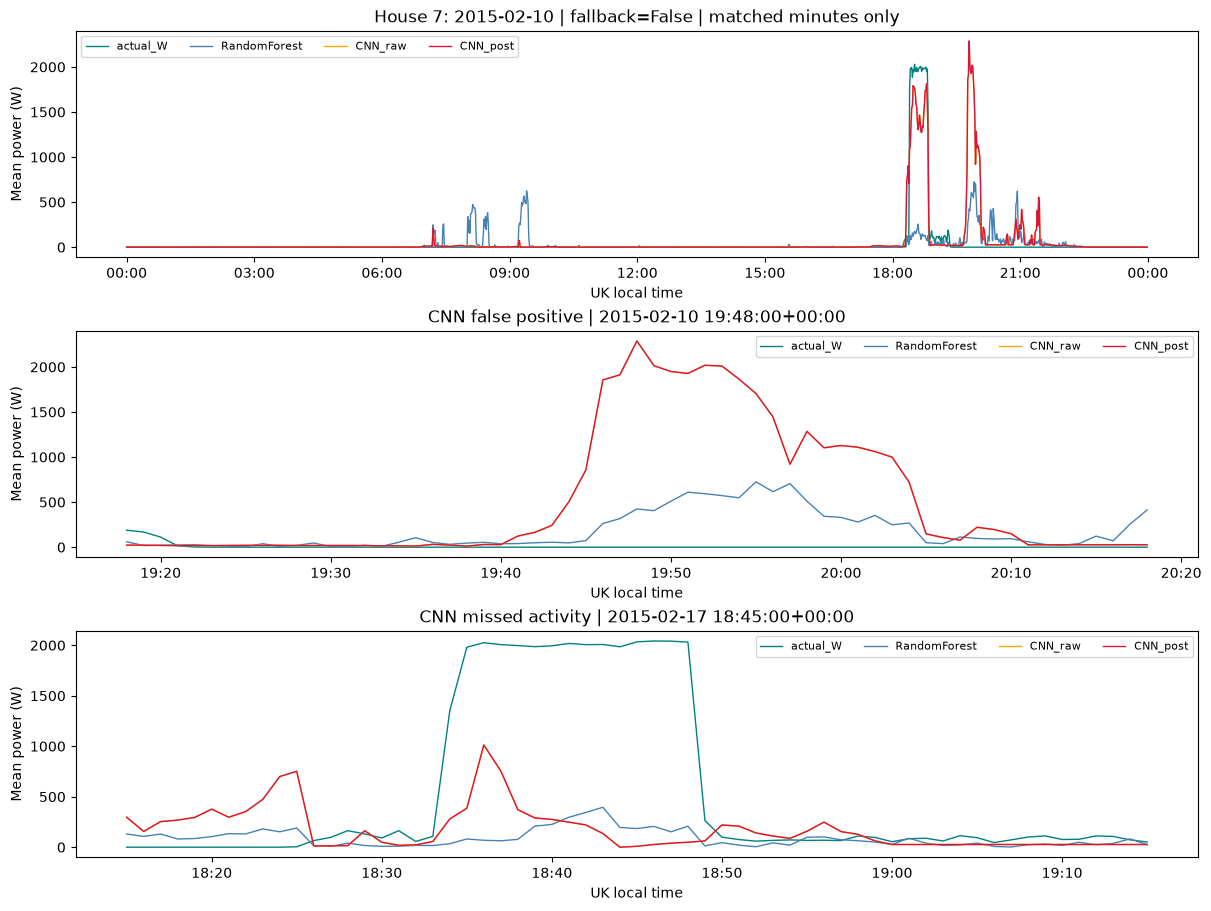

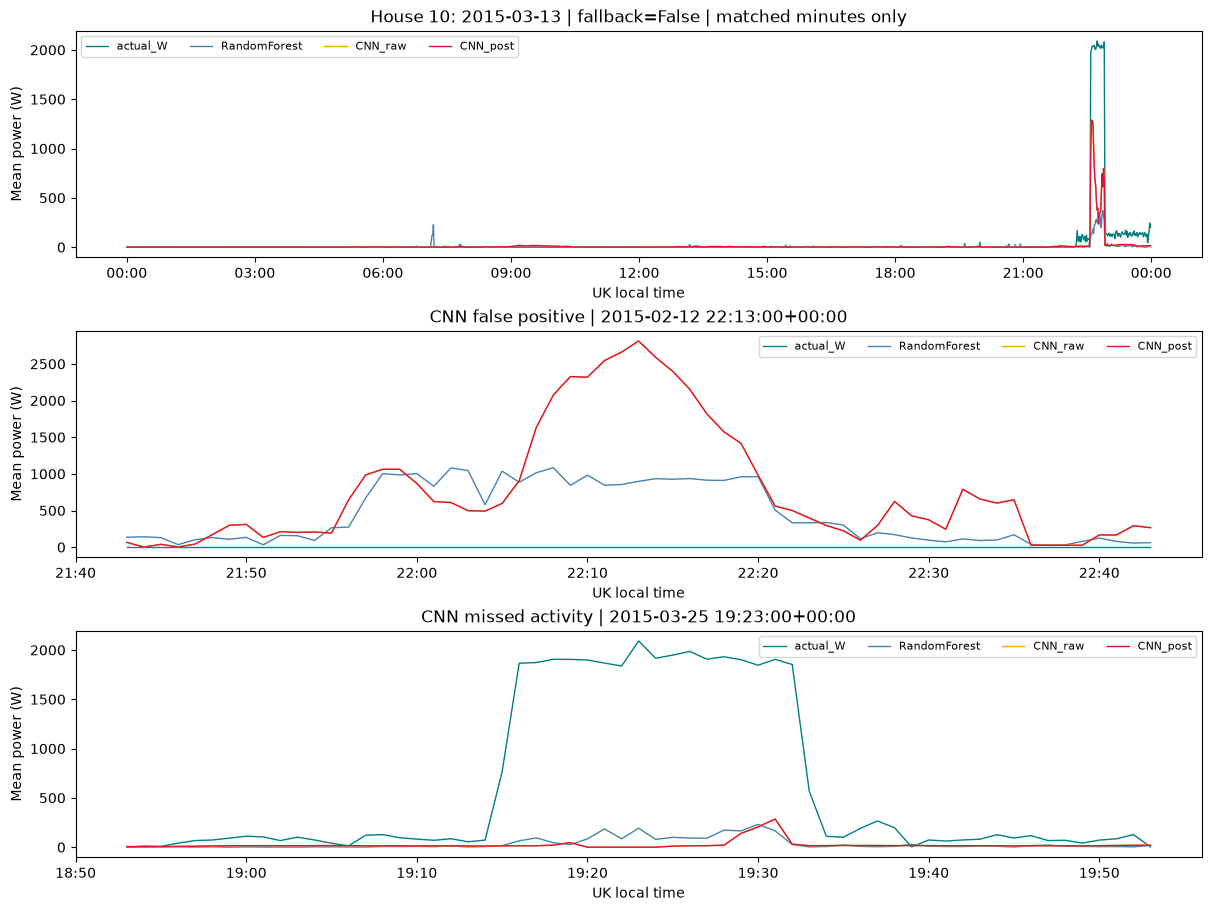

In [8]:
for house,frame in evaluation_frames.items():
    local = frame.tz_convert(LOCAL_TZ)
    daily = local.actual_W.resample('1D').agg(['count','sum'])
    expected = pd.Series([(d+pd.DateOffset(days=1)-d).total_seconds()/60 for d in daily.index],index=daily.index)
    pool = daily[(daily['count']/expected>=.90)&(daily['sum']>0)]
    fallback = pool.empty
    if fallback:
        active = daily[daily['sum']>0]
        pool = active[active['count'].eq(active['count'].max())]
    if pool.empty:
        raise ValueError(f'House {house}: no active day to illustrate')
    day = (pool['sum']-pool['sum'].median()).abs().idxmin()
    day_index = pd.date_range(day,day+pd.DateOffset(days=1),freq='1min',inclusive='left')
    fig,axes = plt.subplots(3,1,figsize=(12,9),layout='constrained')
    trace = local.reindex(day_index)
    colours = {'actual_W':'teal','RandomForest':'steelblue','CNN_raw':'orange','CNN_post':'crimson'}
    for column,colour in colours.items():
        axes[0].plot(trace.index,trace[column],label=column,color=colour,lw=1)
    axes[0].set_title(f'House {house}: {day.date()} | fallback={fallback} | matched minutes only')
    actual_on = local.actual_W>ACTIVE_W
    predicted_on = local.CNN_post>ACTIVE_W
    examples = [(~actual_on&predicted_on,'CNN false positive'),(actual_on&~predicted_on,'CNN missed activity')]
    for ax,(mask,title) in zip(axes[1:],examples):
        if mask.any():
            centre = (local.loc[mask,'CNN_post']-local.loc[mask,'actual_W']).abs().idxmax()
            window = local.reindex(pd.date_range(centre-pd.Timedelta(minutes=30),centre+pd.Timedelta(minutes=30),freq='1min'))
            for column,colour in colours.items():
                ax.plot(window.index,window[column],label=column,color=colour,lw=1)
            ax.set_title(title+' | '+str(centre))
        else:
            ax.text(.5,.5,'No '+title.lower()+' minutes',ha='center',transform=ax.transAxes)
    for ax in axes:
        ax.set(ylabel='Mean power (W)',xlabel='UK local time')
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M',tz=LOCAL_TZ))
        ax.legend(ncol=4,fontsize=8)
    fig.savefig(ROOT/f'figures/part3/seq2point_house{house}.png',dpi=150)
    plt.show()

## 8. Correctness checks and essential outputs

Test midpoint alignment, no windows across NaN outages, training-window household boundaries, strict gap/duration boundaries, no invented bridge wattage, preservation of observation gaps and aggregate caps. Saving never overwrites baseline artifacts. If RF is retained its existing verified joblib file remains the selected model; no rejected CNN model is exported. If CNN wins, save its self-contained normalisation/network in a separate Keras file; selected gap/duration values are recorded in the comparison table and applied with the function above.

In [9]:
# Batched windows must align the middle aggregate sample and target.
a = np.arange(120,dtype=np.float32)
y = a*2
positions = window_centres(a,y)
x_batch,y_batch = next(iter(make_dataset(a,positions,y)))
np.testing.assert_array_equal(x_batch.numpy()[:,HALF,0],a[positions])
np.testing.assert_array_equal(y_batch.numpy()[:,0],y[positions])
a[60] = np.nan
assert len(window_centres(a))==0
for house in TRAIN_HOUSES:
    assert np.all(centres[house]>=HALF) and np.all(centres[house]+HALF<len(GRID))
# Fifteen-minute runs survive; fourteen-minute runs are removed.
aggregate = pd.Series(2000.,index=GRID)
p = pd.Series(np.nan,index=GRID);p.iloc[:40]=0;p.iloc[2:17]=1000;p.iloc[21:35]=1000
clean,state = postprocess(p,aggregate,0,15)
assert clean.iloc[2:17].eq(1000).all() and clean.iloc[21:35].eq(0).all()
# A nine-minute internal pause bridges at max_gap=10; zero wattage remains zero.
p = pd.Series(np.nan,index=GRID);p.iloc[:25]=1000;p.iloc[7:16]=0
clean,state = postprocess(p,aggregate,10,15)
assert state.iloc[7:16].all() and clean.iloc[7:16].eq(0).all()
p.iloc[7:17]=0
_,state = postprocess(p,aggregate,10,0)
assert not state.iloc[7:17].any()
p.iloc[12]=np.nan
clean,_ = postprocess(p,aggregate,10,15)
assert pd.isna(clean.iloc[12])
_,identity = postprocess(pd.Series(np.nan,index=GRID),aggregate)
assert not identity.any()
for house,frame in evaluation_frames.items():
    for name in ['RandomForest','CNN_raw','CNN_post']:
        assert frame[name].between(0,frame.aggregate_W+1e-5).all()
        assert np.isfinite(frame[name]).all()
comparison['recommended_model'] = selected_name
comparison['selected_max_gap_minutes'] = chosen_gap
comparison['selected_min_duration_minutes'] = chosen_duration
comparison.to_csv(ROOT/'results/seq2point_comparison.csv',index=False)
if selected_name!='RandomForest':
    model_path = ROOT/'results/seq2point_selected.keras'
    cnn.save(model_path)
    loaded = tf.keras.models.load_model(model_path,compile=False)
    sample_x,_ = next(iter(validation_ds))
    np.testing.assert_allclose(loaded(sample_x,training=False),cnn(sample_x,training=False),rtol=1e-5,atol=1e-4)
    print('Selected CNN saved and reloaded; apply its selected offline policy after inference.')
else:
    print('RF retained; existing results/washing_machine_model.joblib is unchanged.')
print('Window, mask, duration, observation-gap and bounded-output checks passed.')

RF retained; existing results/washing_machine_model.joblib is unchanged.
Window, mask, duration, observation-gap and bounded-output checks passed.


## Conclusions to read with the measured results

Do not claim a CNN advantage from validation loss or one attractive trace. Use the paired table, high-power errors, false-positive/missed-minute counts and coverage. A mask-only improvement is not an energy improvement. The CNN uses future information and full-run processing can require further look-ahead, so an accuracy benefit would not establish immediate real-time suitability.

The experiment has one random seed, one architecture, one reused validation home, two retrospective evaluation homes and one season. Official fill/zero ambiguity and meter asynchrony remain; missing labels/history are excluded consistently. Repeated validation use and post-processing choices can overfit House 5. This is a controlled experiment, not a demonstrated state-of-the-art benchmark, production deployment or billing model. Report actual training cost and any regressions; keep RF unless the predeclared validation conditions support replacement.

## Measured outcome: RF remains the selected model

One **93,561-parameter** CNN trained on **491,762** valid training windows. CPU training took **89.9 seconds** for seven epochs; early stopping restored **epoch 5**. The maximum was ten epochs. The RF was loaded rather than retrained. Installation and data preparation are not included in this training time. `tf.data` performs seeded training shuffling; Keras's ignored shuffle flag is set explicitly to False.

### Paired results on identical minutes

| split | model | precision | recall | F1 | RMSE_W | false_positive_minutes | missed_active_minutes | daily_energy_error_percent | high_power_MAE_W |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| validation | RandomForest | 0.266 | 0.398 | 0.319 | 205.584 | 12160 | 6654 | 91.284 | 1722.752 |
| validation | CNN_raw | 0.367 | 0.227 | 0.281 | 202.24 | 4332 | 8543 | 85.183 | 1689.226 |
| test_house7 | RandomForest | 0.408 | 0.768 | 0.533 | 220.01 | 11423 | 2380 | 41.004 | 1510.917 |
| test_house7 | CNN_raw | 0.534 | 0.813 | 0.645 | 161.467 | 7289 | 1914 | 35.294 | 558.158 |
| test_house10 | RandomForest | 0.306 | 0.712 | 0.428 | 172.276 | 13790 | 2463 | 77.616 | 1290.353 |
| test_house10 | CNN_raw | 0.464 | 0.695 | 0.557 | 157.024 | 6860 | 2602 | 66.153 | 852.7 |

No processing rule passed the declared validation criteria, so `CNN_post` is the identity policy (gap=0, duration=0) and exactly matches `CNN_raw`. The proposed gap=10/minimum duration=15 rule reduced House 5 recall further (22.7% -> 19.9%), F1 (0.281 -> 0.257), and worsened daily energy error (85.2% -> 86.3%). Event-mask F1 is reported separately and is not used as a substitute for wattage-derived detection.

**House 5 is the selection evidence:** CNN precision improves (26.6% -> 36.7%) and false positives drop (12,160 -> 4,332), but recall falls by about 17 percentage points (39.8% -> 22.7%); missed active minutes increase (6,654 -> 8,543). F1 falls from 0.319 to 0.281. Net bias becomes more negative (-38.4% -> -64.2%) even though daily absolute energy error improves (91.3% -> 85.2%). High-power MAE improves only about 1.9% (1722.8 -> 1689.2 W). This does not justify replacing RF under the rule fixed before evaluation.

**Retrospective House 7:** CNN F1 improves 0.533 -> 0.645, false positives fall 11,423 -> 7,289, missed active minutes fall 2,380 -> 1,914, RMSE falls 220.0 -> 161.5 W and high-power MAE falls 1510.9 -> 558.2 W. Daily energy error improves 41.0% -> 35.3%, but net bias changes from underestimation (-28.7%) to overestimation (+27.3%). The traces still include large false heating-like pulses and missed genuine pulses.

**Retrospective House 10:** CNN F1 improves 0.428 -> 0.557, false positives fall 13,790 -> 6,860 and RMSE falls 172.3 -> 157.0 W. High-power MAE improves 1290.4 -> 852.7 W and daily energy error improves 77.6% -> 66.2%. However, recall decreases 71.2% -> 69.5% and missed active minutes increase 2,463 -> 2,602. Improved average high-power error does not mean every heating pulse was recovered.

These are promising **offline, household-dependent** results, not proof that CNN is generally better. The 49 future minutes give information unavailable to the causal RF at prediction time. The observed difference between House 5 and the evaluation homes is a generalisation warning; its exact cause has not been established. Switching to CNN because its retrospective results look better would select on evaluation data. Therefore retain RF and its existing saved model, and do not rerun architecture/threshold searches against these homes.

### Coverage and unchanged full-coverage reference

The primary table uses 118,478 House 5, 122,638 House 7 and 118,417 House 10 matched minutes. Relative to RF eligibility, this excludes an additional 2,599, 735 and 1,451 minutes, respectively, because the CNN needs future context. Energy totals use only these identical valid minutes, never fill excluded minutes with zero.

The following original RF numbers are context only; they were not overwritten and must not be confused with the paired cohort:

| house | minutes_baseline_full | F1_baseline_full | minutes_matched | F1_matched |
| --- | --- | --- | --- | --- |
| 5 | 121077 | 0.322 | 118478 | 0.319 |
| 7 | 123373 | 0.532 | 122638 | 0.533 |
| 10 | 119868 | 0.427 | 118417 | 0.428 |

### Verification and saved artifacts

All nine code cells executed sequentially in a fresh TensorFlow kernel. The original data preparation, RF feature function, metric and prediction functions were checked identical to baseline. Passed midpoint/target alignment, household-contained centre bounds, no windows crossing a NaN outage, strict gap and minimum-duration boundaries, no invented watts in bridged pauses, missing-gap preservation and finite aggregate-bounded predictions. Original baseline model/results/notebooks/figures and Parts 1/2 were checked unchanged after execution.

Saved only `results/seq2point_comparison.csv` and two `figures/part3/seq2point_house*.png` figures in addition to this notebook. The final selected model remains the existing `results/washing_machine_model.joblib`; a rejected CNN was not exported. TensorFlow and its required packages reside in the Git-ignored `.venv`; the baseline Python environment was not changed. No additional execution scripts, manifests or diagnostic exports were created.
